In [21]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [22]:
PCA_DIR = Path("../results/pca_sign")
OTHER_ATTACK_DIR = Path("../results/other_attacks")

In [23]:
CLEAN_BASELINE_DIR = Path("../results/clean_baseline")

In [24]:
def load_result(path):
    df = pd.read_csv(path)

    df["round"] = pd.to_numeric(
        df["round"],
        errors="coerce"
    )

    df["test_accuracy"] = pd.to_numeric(
        df["test_accuracy"],
        errors="coerce"
    )

    df = (
        df
        .dropna(subset=["round", "test_accuracy"])
        .sort_values("round")
        .reset_index(drop=True)
    )

    return df

In [30]:
ATTACK_COLORS = {
    "Clean": "black",
    "PCA Single-PC (PC2, -)": "tab:blue",
    "PCA STD-Weighted (k=3, +)": "tab:orange",
    "sign_flip": "tab:red",
    "min_max": "tab:green",
    "min_sum": "tab:purple",
    "alie": "tab:brown",
    "alie_optim": "tab:pink",
}

In [31]:
def plot_attack_comparison(aggregator):
    experiments = {}
    # -----------------------------
    # Clean baseline
    # -----------------------------
    clean_path = (
        CLEAN_BASELINE_DIR
        / f"{aggregator}_noniid_clean_baseline.csv"
    )

    if clean_path.exists():
        experiments["Clean"] = clean_path
    else:
        print(f"Missing: {clean_path.name}")
    # -----------------------------
    # Best Single-PC PCA
    # PC2, sign = -1
    # -----------------------------
    single_pc_path = (
        PCA_DIR
        / f"{aggregator}_pc2_m1.csv"
    )

    if single_pc_path.exists():
        experiments["PCA Single-PC (PC2, -)"] = single_pc_path
    else:
        print(f"Missing: {single_pc_path.name}")

    # -----------------------------
    # Best STD-weighted PCA
    # top-k = 3, sign = +1
    # -----------------------------
    std_path = (
        PCA_DIR
        / f"{aggregator}_std_weighted_k3_p1.csv"
    )

    if std_path.exists():
        experiments["PCA STD-Weighted (k=3, +)"] = std_path
    else:
        print(f"Missing: {std_path.name}")

    # -----------------------------
    # Other attacks
    # -----------------------------
    for path in OTHER_ATTACK_DIR.glob(
        f"{aggregator}_*.csv"
    ):
        attack_name = path.stem.removeprefix(
            f"{aggregator}_"
        )

        experiments[attack_name] = path

    # -----------------------------
    # Plot
    # -----------------------------
    plt.figure(figsize=(11, 7))

    for label, path in experiments.items():
        df = load_result(path)

        plt.plot(
            df["round"],
            df["test_accuracy"],
            marker="o",
            markersize=3,
            linewidth=2,
            label=label,
            color=ATTACK_COLORS.get(label),
        )

    plt.xlabel("Round")
    plt.ylabel("Test Accuracy")

    plt.title(
        f"Attack Comparison - {aggregator}"
    )

    plt.ylim(0, 1)

    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.show()

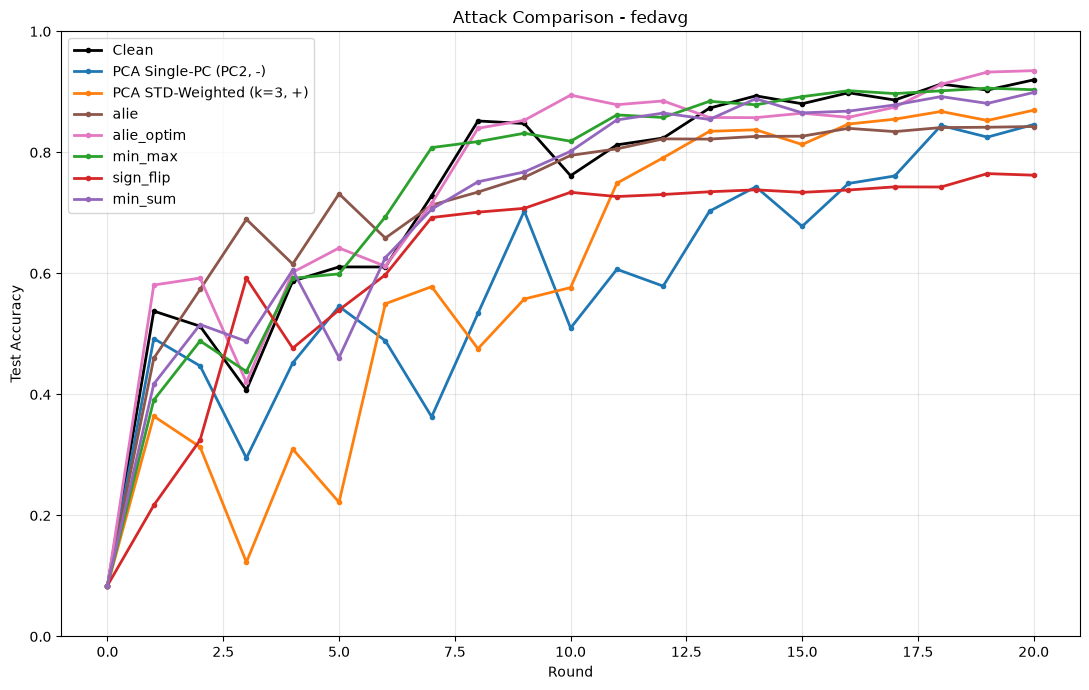

In [32]:
plot_attack_comparison("fedavg")

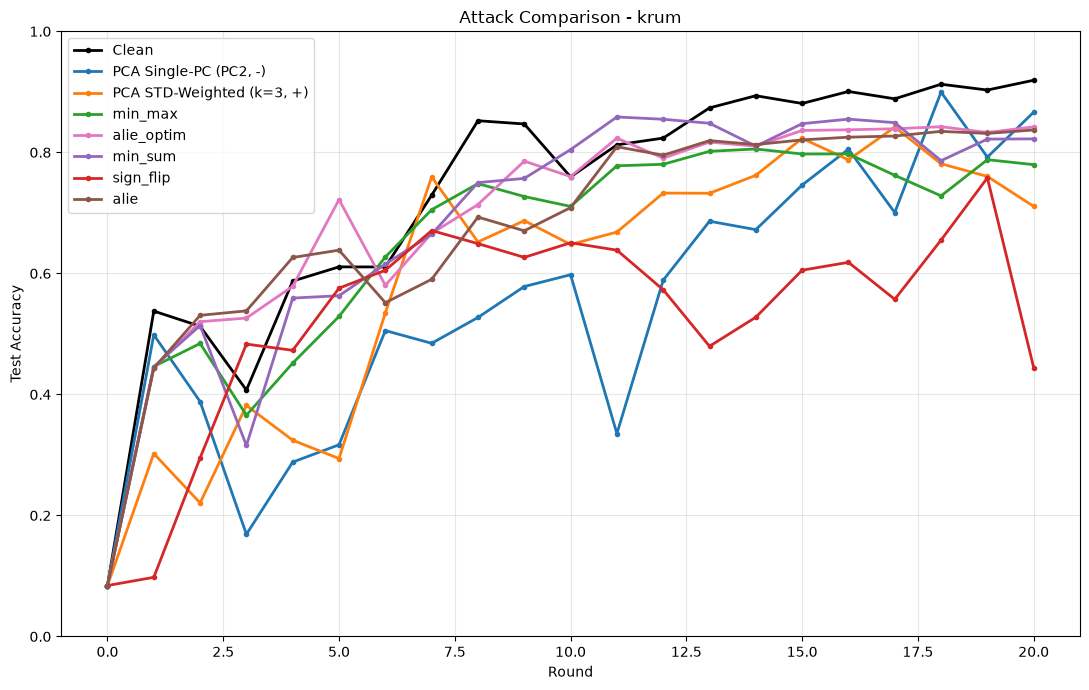

In [33]:
plot_attack_comparison("krum")

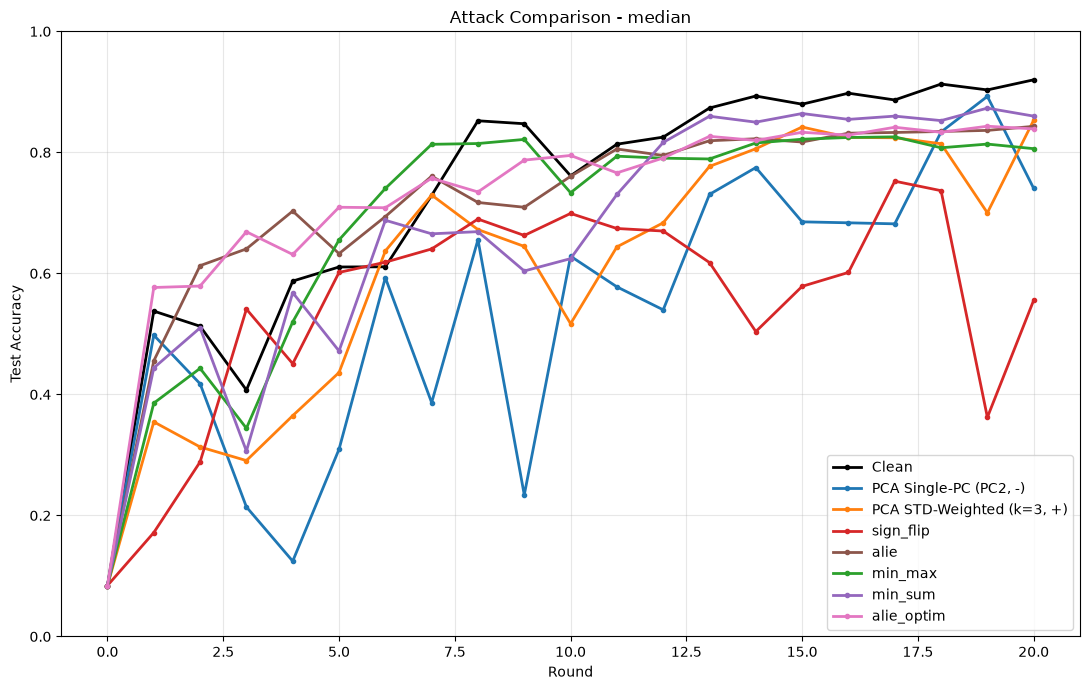

In [34]:
plot_attack_comparison("median")

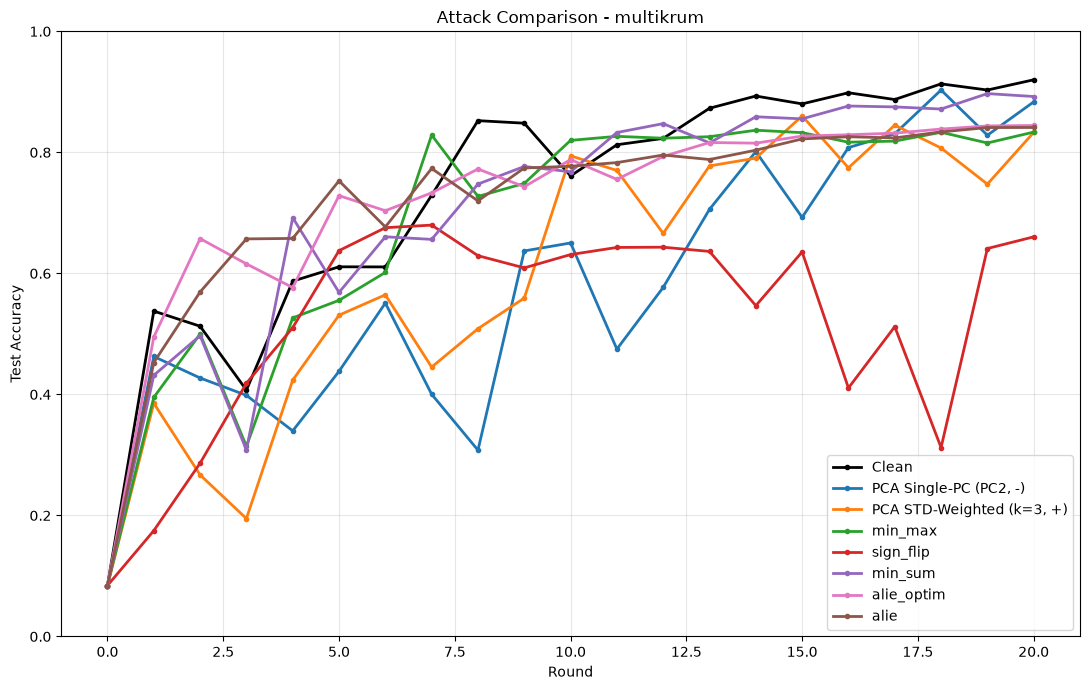

In [35]:
plot_attack_comparison("multikrum")

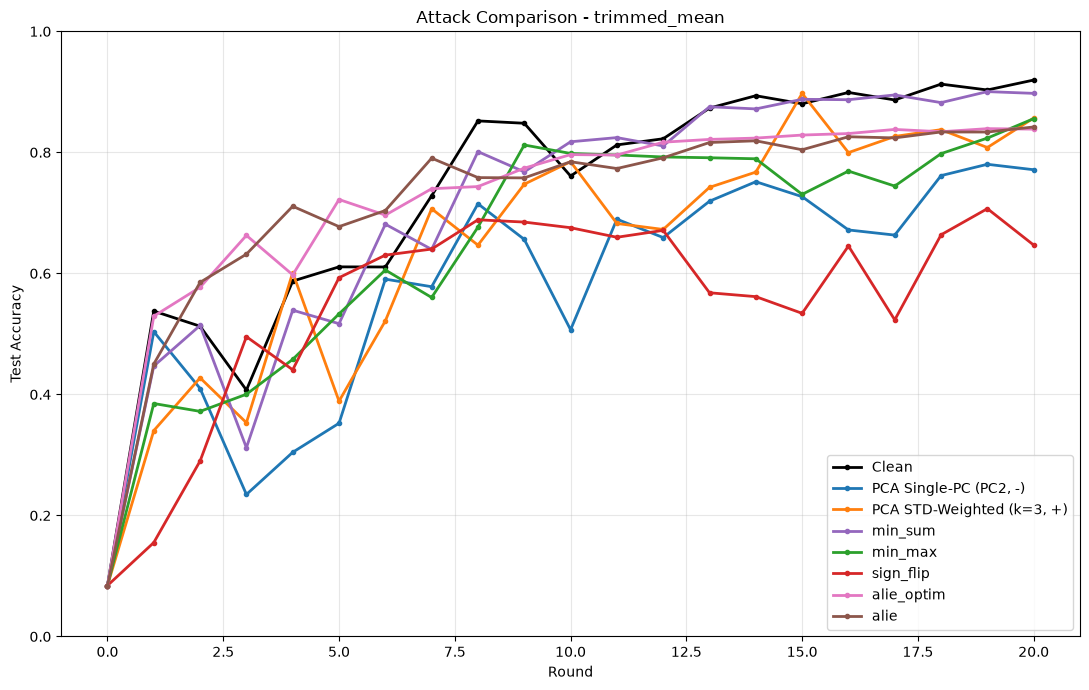

In [36]:
plot_attack_comparison("trimmed_mean")